# Logistic regression: predict position (multi-position aware)
**Task:** classify outfield players as DF / MF / FW from playing-style stats, with position hidden.

**Fix:** a player listed as `MF,FW` is now **correct if the prediction is either MF or FW**. Training also respects this: a dual-position player contributes one row per listed position, each weighted `1/n`, so the model isn't punished for either answer.

**Leakage guard:** the train/test split is done per player *before* expanding rows, so no player appears in both sets. No `Pos` or `Pos_stats_*` column is a feature.

In [ ]:
%pip install -q scikit-learn pandas numpy matplotlib

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
df = pd.read_csv('players_data-2026_2027.csv'); print(df.shape)

(2295, 102)


In [2]:
d = df[df['Pos'].notna() & ~df['Pos'].str.contains('GK')].copy()
d = d[d['90s'] >= 3].drop_duplicates(subset=['Player','Squad']).reset_index(drop=True)
names = ['DF','MF','FW']
d['pos_set'] = d['Pos'].str.split(',').apply(lambda l: [p.strip() for p in l if p.strip() in names])
d = d[d['pos_set'].str.len() > 0].reset_index(drop=True)
d['multi'] = d['pos_set'].str.len() > 1

counts = ['Gls','Ast','Sh','SoT','Crs','Int','TklW','Fld','Fls','Off','CrdY','CrdR','PKatt']
for k in counts: d[k+'_90'] = d[k] / d['90s']
feats = [k+'_90' for k in counts] + ['Age','Min%','Mn/Start','Starts','90s']
feats = [f for f in feats if f in d.columns]
d[feats] = d[feats].fillna(0)
assert not any('Pos' in f for f in feats)
print(len(d), 'players |', d['multi'].sum(), 'list more than one position')

1268 players | 227 list more than one position


In [3]:
def expand(frame):
    rows = frame.explode('pos_set')
    w = 1.0 / frame['pos_set'].str.len().loc[rows.index]
    return rows[feats], rows['pos_set'].map({n:i for i,n in enumerate(names)}), w

def set_accuracy(model, frame):
    pred = model.predict(frame[feats])
    ok = [names[p] in s for p, s in zip(pred, frame['pos_set'])]
    return np.mean(ok), pred, np.array(ok)

def make(): return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

tr, te = train_test_split(d, test_size=0.2, random_state=42)
Xtr, ytr, wtr = expand(tr)
clf = make(); clf.fit(Xtr, ytr, logisticregression__sample_weight=wtr)
acc, pred, ok = set_accuracy(clf, te)
first = te['pos_set'].str[0].map({n:i for i,n in enumerate(names)}).values
print('Test accuracy (any listed position counts): %.3f' % acc)
print('Old metric (first-listed position only):     %.3f' % (pred == first).mean())
print('Single-position players: %.3f | Multi-position players: %.3f' % (ok[~te['multi'].values].mean(), ok[te['multi'].values].mean()))

Test accuracy (any listed position counts): 0.823
Old metric (first-listed position only):     0.776
Single-position players: 0.796 | Multi-position players: 0.953


In [4]:
accs = []
for a, b in KFold(5, shuffle=True, random_state=42).split(d):
    X_, y_, w_ = expand(d.iloc[a]); m_ = make(); m_.fit(X_, y_, logisticregression__sample_weight=w_)
    accs.append(set_accuracy(m_, d.iloc[b])[0])
print('5-fold accuracy (any listed position counts): %.3f +/- %.3f' % (np.mean(accs), np.std(accs)))

5-fold accuracy (any listed position counts): 0.817 +/- 0.021


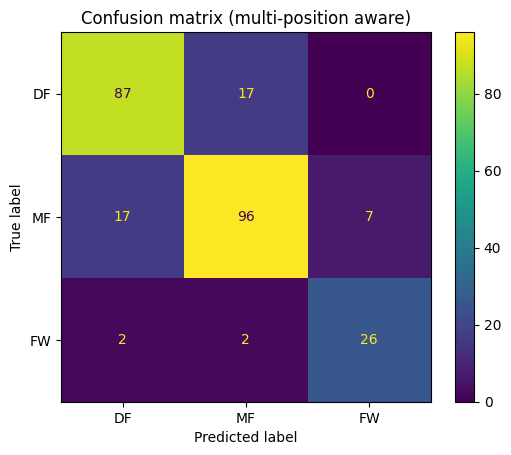

In [5]:
# Confusion matrix: if the prediction is valid, count it under the true class it matched
true_for_cm = [names[p] if names[p] in s else s[0] for p, s in zip(pred, te['pos_set'])]
ConfusionMatrixDisplay(confusion_matrix(true_for_cm, [names[p] for p in pred], labels=names), display_labels=names).plot()
plt.title('Confusion matrix (multi-position aware)'); plt.show()

In [6]:
proba = pd.DataFrame(clf.predict_proba(te[feats]), columns=names, index=te.index).round(2)
res = pd.concat([te[['Player','Squad','Pos']], proba], axis=1)
res['pred'] = [names[p] for p in pred]; res['correct'] = ok
print('Wrong even with multi-position credit, most confident first')
res[~res.correct].assign(conf=proba.max(axis=1)).sort_values('conf', ascending=False).head(15)

Wrong even with multi-position credit, most confident first


,Player,Squad,Pos,DF,MF,FW,pred,correct,conf
58,Jon Aramburu,Real Sociedad,DF,0.10,0.90,0.00,MF,False,0.90
888,Fredrik Oppegard,Auxerre,MF,0.88,0.12,0.00,DF,False,0.88
919,Adrià Pedrosa,Rayo Vallecano,DF,0.11,0.85,0.05,MF,False,0.85
543,Merwan Ifnaoui,Troyes,"FW,MF",0.78,0.22,0.00,DF,False,0.78
548,Isco,Real Betis,MF,0.00,0.23,0.77,FW,False,0.77
471,Matt Grimes,Coventry City,MF,0.75,0.23,0.01,DF,False,0.75
746,Ephron Mason-Clark,Coventry City,MF,0.00,0.26,0.74,FW,False,0.74
952,Puga,Málaga,DF,0.28,0.72,0.00,MF,False,0.72
490,Miguel Gutiérrez,Leverkusen,DF,0.26,0.72,0.01,MF,False,0.72
588,Jesper Karlström,Udinese,MF,0.71,0.28,0.02,DF,False,0.71
